# Diffusion–RGC hyperparameter analysis

This notebook analyses the RMS-normalized guidance search in `hyperparameter_search_bedroom`. Each row is a saved direct noisy diffusion state $x_{t-1}$, rather than the denoiser's predicted clean image $\hat{x}_0$.

The results contain one fixed $\sigma_r=1$, so an $\eta$–$\sigma_r$ surface cannot be estimated from this run. Instead, the 3D plots show the two quantities that vary here: RGC guidance strength $\eta$ and completed reverse-diffusion steps $T$.

In [13]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import ticker
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from PIL import Image

plt.rcParams.update({
    'figure.dpi': 130,
    'savefig.dpi': 300,
    'font.size': 14,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

SEARCH_DIR = Path('hyperparameter_search_bedroom2')
RESULTS_PATH = SEARCH_DIR / 'results.csv'
RECONSTRUCTION_DIR = SEARCH_DIR / 'reconstructions'
TARGET_PATH = SEARCH_DIR / './lnp_naturalmovies/bedroom2.png'  # Optional: set to the source target image if it is available.

results = pd.read_csv(RESULTS_PATH).sort_values(['eta', 'T']).reset_index(drop=True)
expected_columns = {'eta', 'sigma_r', 'T', 'mse', 'final_rgc_loss', 'seed'}
missing_columns = expected_columns.difference(results.columns)
if missing_columns:
    raise ValueError(f'Missing expected CSV columns: {sorted(missing_columns)}')

etas = np.sort(results['eta'].unique())
timesteps = np.sort(results['T'].unique())
sigmas = np.sort(results['sigma_r'].unique())
print(f'Loaded {len(results):,} checkpoints from {RESULTS_PATH}')
print(f'eta values: {len(etas)} | T values: {len(timesteps)} | sigma_r values: {sigmas}')
if len(sigmas) == 1:
    print('Note: sigma_r was fixed, so this run supports eta–T, not eta–sigma_r, response surfaces.')

best_mse = results.loc[results['mse'].idxmin()]
best_rgc = results.loc[results['final_rgc_loss'].idxmin()]
display(pd.DataFrame([best_mse, best_rgc], index=['Lowest MSE', 'Lowest RGC loss']))

Loaded 200 checkpoints from hyperparameter_search_bedroom2/results.csv
eta values: 10 | T values: 20 | sigma_r values: [1.]
Note: sigma_r was fixed, so this run supports eta–T, not eta–sigma_r, response surfaces.


,eta,sigma_r,T,mse,final_rgc_loss,seed
Lowest MSE,0.013296,1.0,100.0,0.004621,0.000005,1234.0
Lowest RGC loss,0.005000,1.0,100.0,0.005525,0.000003,1234.0


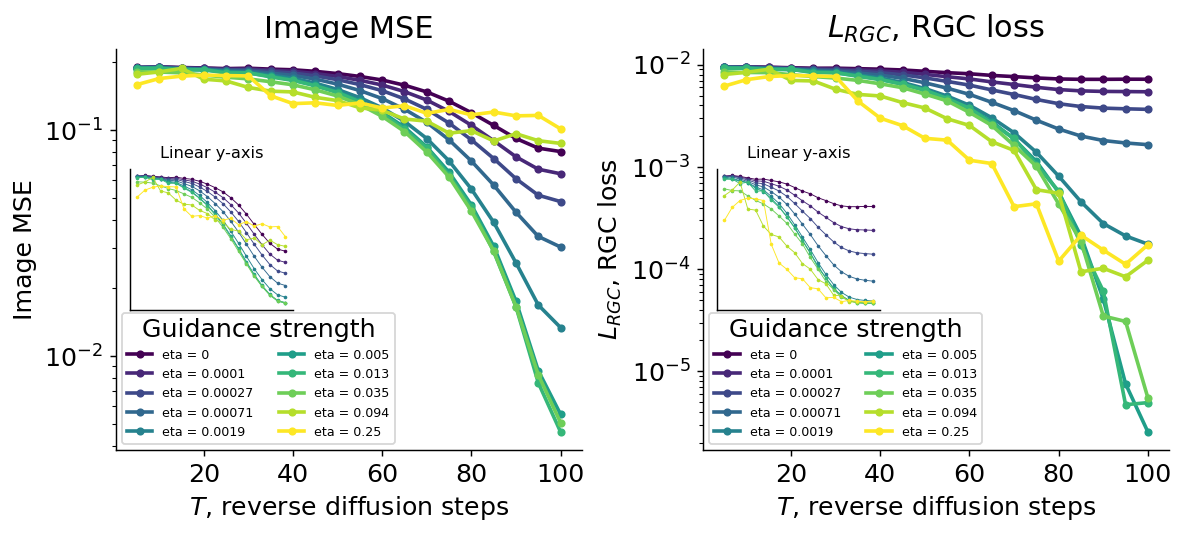

In [14]:
# A log x-axis cannot display eta=0. Plot it at one third of the smallest positive eta,
# while retaining an explicit tick label of 0.
positive_etas = etas[etas > 0]
eta_plot = {0.0: positive_etas.min() / 3, **{eta: eta for eta in positive_etas}}
eta_ticks = [eta_plot[eta] for eta in etas]
eta_labels = ['0' if eta == 0 else f'{eta:.1g}' for eta in etas]

fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
metrics = [('mse', 'Image MSE', 'viridis'), ('final_rgc_loss', '$L_{{RGC}}$, RGC loss', 'viridis')]

for ax, (metric, ylabel, cmap_name) in zip(axes, metrics):
    cmap = plt.get_cmap(cmap_name)

    # inset plot
    inset_pos = [0.03, 0.35, 0.35, 0.35] 
    ax_inset = ax.inset_axes(inset_pos)

    for index, eta in enumerate(etas):
        curve = results[results['eta'] == eta].sort_values('T')
        ax.plot(curve['T'], curve[metric], color=cmap(index / max(len(etas) - 1, 1)), linewidth=2, marker='o', markersize=3.5, label='eta = 0' if eta == 0 else f'eta = {eta:.2g}')

        ax_inset.plot(curve['T'], curve[metric], color=cmap(index / max(len(etas) - 1, 1)), linewidth=0.5, marker='o', markersize=1, label='eta = 0' if eta == 0 else f'eta = {eta:.2g}')
        ax_inset.set_title('Linear y-axis', fontsize=9)
        ax_inset.set_xticks([])
        ax_inset.set_yticks([])
    
    ax.set_title(f'{ylabel}')
    ax.set_xlabel('$T$, reverse diffusion steps')
    ax.set_ylabel(ylabel)
    ax.legend(title='Guidance strength', fontsize=7, ncol=2)
    ax.set_yscale("log")

#axes[1].set_yscale('log')
plt.show()

<>:10: SyntaxWarning: invalid escape sequence '\e'
<>:10: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_3614889/143433348.py:10: SyntaxWarning: invalid escape sequence '\e'
  ax.set_ylabel('$\eta$, RGC likelihood guidance')


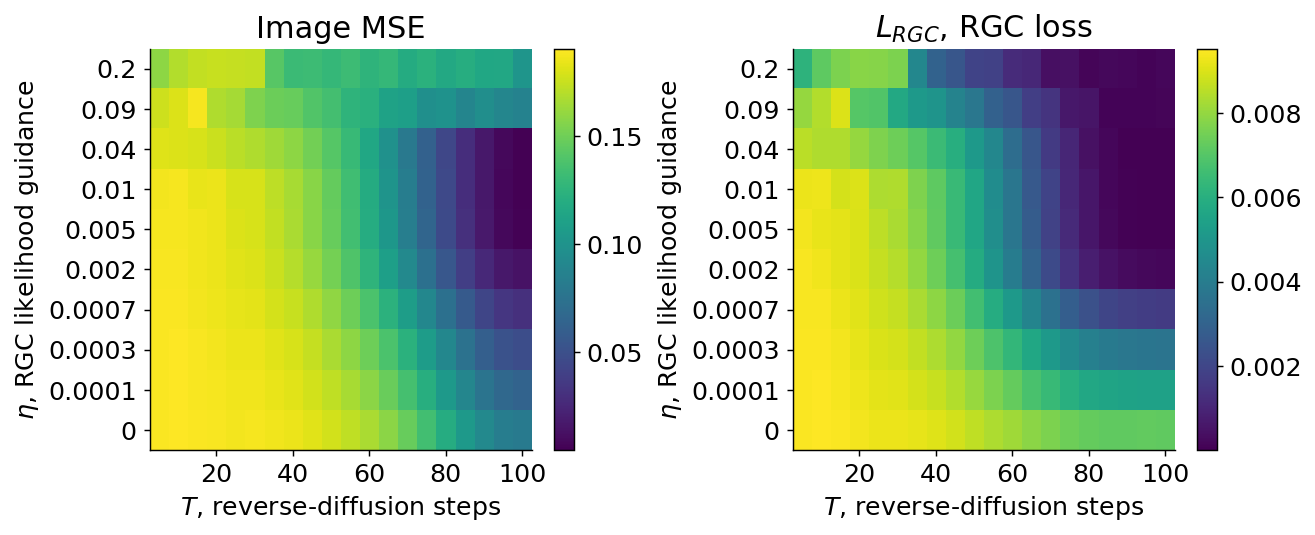

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, (metric, ylabel, cmap_name) in zip(axes, metrics):
    matrix = results.pivot(index='eta', columns='T', values=metric).loc[etas, timesteps]
    image = ax.imshow(
        matrix.to_numpy(), aspect='auto', origin='lower', cmap=cmap_name,
        extent=[timesteps.min() - 2.5, timesteps.max() + 2.5, -0.5, len(etas) - 0.5],
    )
    ax.set_title(f'{ylabel}')
    ax.set_xlabel('$T$, reverse-diffusion steps')
    ax.set_ylabel('$\eta$, RGC likelihood guidance')
    ax.set_yticks(np.arange(len(etas)), eta_labels)
    colorbar = fig.colorbar(image, ax=ax, pad=0.02)
    #colorbar.set_label(ylabel, labelpad=-40)

plt.show()

<>:16: SyntaxWarning: invalid escape sequence '\e'
<>:16: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_3614889/485112181.py:16: SyntaxWarning: invalid escape sequence '\e'
  ax.set_ylabel('$\eta$, RGC guidance', labelpad=9)
/home/rotation/anaconda3/envs/lnp_torch/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


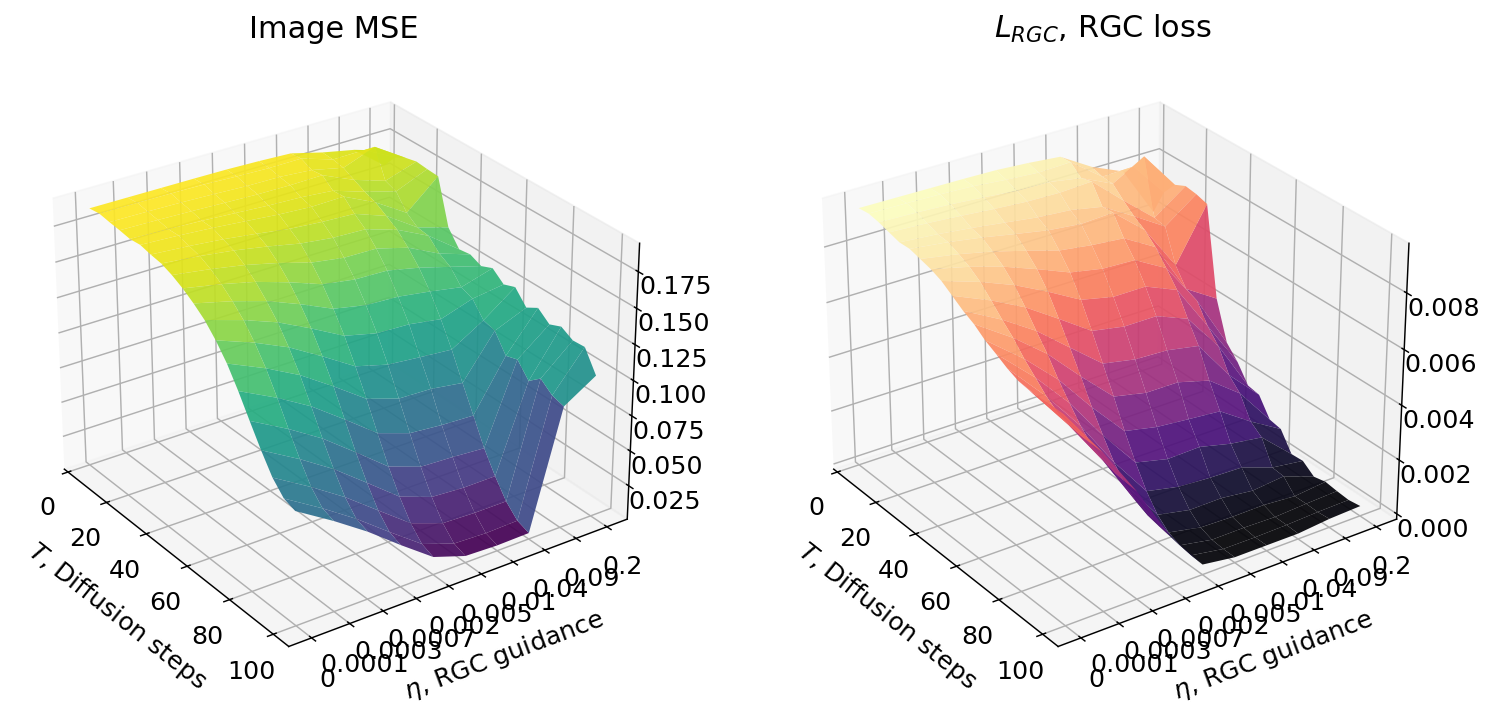

In [16]:
from matplotlib.animation import FuncAnimation

fig = plt.figure(figsize=(14, 7), constrained_layout=True)
axes = [fig.add_subplot(1, 2, i + 1, projection='3d') for i in range(2)]

T_grid, eta_grid_values = np.meshgrid(timesteps, etas)
eta_grid_log = np.log10(np.vectorize(eta_plot.get)(eta_grid_values))

for ax, (metric, title, cmap_name) in zip(axes, [('mse', 'Image MSE', 'viridis'), ('final_rgc_loss', '$L_{{RGC}}$, RGC loss', 'magma')]):

    Z = results.pivot(index='eta', columns='T', values=metric).loc[etas, timesteps].to_numpy()
    surface = ax.plot_surface(T_grid, eta_grid_log, Z, cmap=cmap_name, edgecolor='none', alpha=0.92)

    ax.set_title(f'{title}')
    ax.set_xlabel('$T$, Diffusion steps', labelpad=8)
    ax.set_ylabel('$\eta$, RGC guidance', labelpad=9)
    #ax.set_zlabel(title, labelpad=8)
    ax.set_yticks(np.log10(eta_ticks), eta_labels)
    ax.view_init(elev=28, azim=-35)
    #ax.invert_xaxis()
    #ax.invert_yaxis()

    #fig.colorbar(surface, ax=ax, shrink=0.62, pad=0.1, label=title)

plt.show()

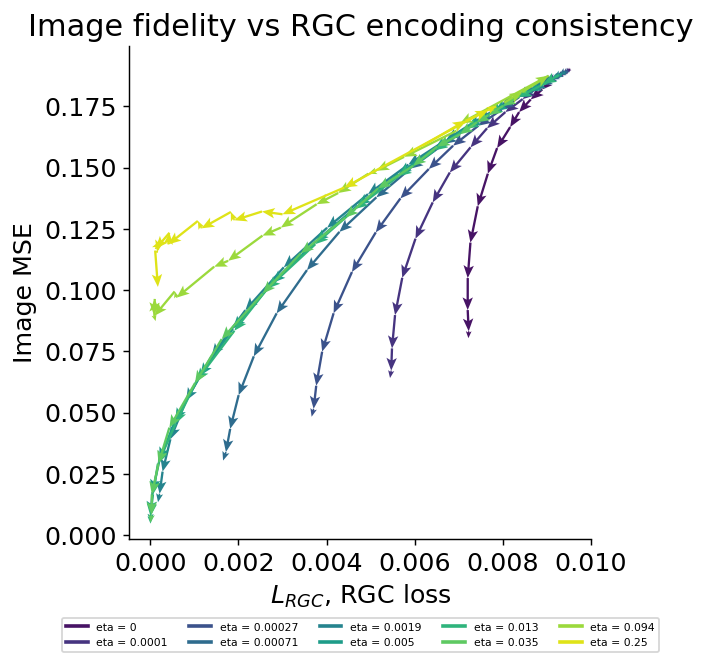

In [17]:
# Arrowed trajectories show how each eta moves through (RGC loss, MSE) over T.
fig, ax = plt.subplots(figsize=(5, 5), constrained_layout=True)
eta_colors = plt.get_cmap("viridis")(np.linspace(0.05, 0.95, len(etas)))

for eta, color in zip(etas, eta_colors):
    trajectory = results[results["eta"] == eta].sort_values("T")
    x = trajectory["final_rgc_loss"].to_numpy()
    y = trajectory["mse"].to_numpy()

    # Checkpoint locations.
    # ax.scatter(x, y, s=28, color=color, alpha=0.9, edgecolors="white", linewidths=0.35, zorder=2)

    # Direction of increasing T.
    ax.quiver(x[:-1], y[:-1], np.diff(x), np.diff(y), color=color, alpha=1, angles="xy", scale_units="xy", scale=1, width=0.005, headwidth=4.5, headlength=5.5, headaxislength=4.5, zorder=1)

    ax.plot([], [], color=color, linewidth=2, label=f"eta = {eta:.2g}")

# Use color—not marker shape—to distinguish the two optima.
# ax.scatter(best_mse["final_rgc_loss"], best_mse["mse"], s=115, color="tab:red", edgecolor="black", linewidth=0.7, zorder=4, label="Lowest MSE")
# ax.scatter(best_rgc["final_rgc_loss"], best_rgc["mse"], s=115, color="tab:blue", edgecolor="black", linewidth=0.7, zorder=4, label="Lowest RGC loss")

#ax.set_xscale("log")
#ax.set_yscale("log")
ax.set_xlabel("$L_{{RGC}}$, RGC loss")
ax.set_ylabel("Image MSE")
ax.set_title("Image fidelity vs RGC encoding consistency")
ax.legend(bbox_to_anchor=(0.5, -0.15), ncol=5, loc="upper center", fontsize=6)
plt.show()

<>:18: SyntaxWarning: invalid escape sequence '\e'
<>:18: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_3614889/474269983.py:18: SyntaxWarning: invalid escape sequence '\e'
  ax.text(5, 45, f"$\eta={row['eta']:.2g}$\n$MSE={row['mse']:.4f}$\n$L_{{RGC}}={row["final_rgc_loss"]:.4f}$", c="blue", fontsize=10)


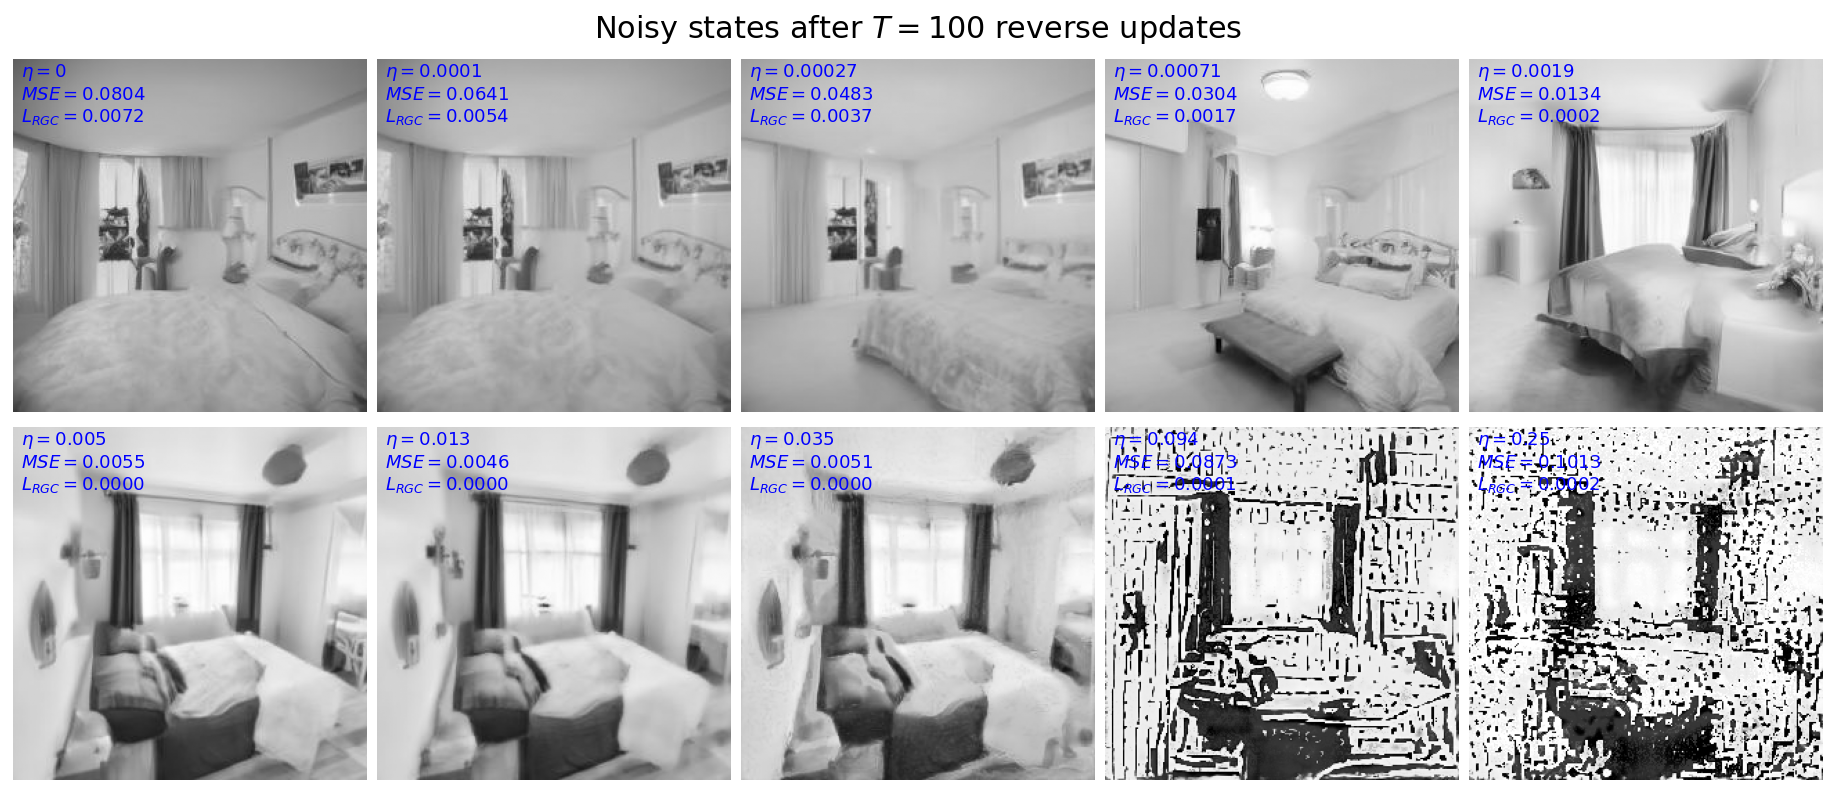

In [18]:
def result_filename(row):
    eta = float(row['eta'])
    sigma_r = float(row['sigma_r'])
    eta_tag = '0' if eta == 0 else f'{eta:.4g}'.replace('.', 'p').replace('-', 'm')
    sigma_tag = f'{sigma_r:g}'.replace('.', 'p')
    return RECONSTRUCTION_DIR / f"reconstruction__eta_{eta_tag}__sigma_r_{sigma_tag}__T_{int(row['T']):03d}.png"

# Compare every eta at the final saved noisy state. Rows are sorted from no guidance to strong guidance.
final_step_results = results[results['T'] == timesteps.max()].sort_values('eta')
fig, axes = plt.subplots(2, 5, figsize=(14, 6), constrained_layout=True)
for ax, (_, row) in zip(axes.flat, final_step_results.iterrows()):
    image_path = result_filename(row)
    if image_path.exists():
        ax.imshow(Image.open(image_path), cmap='gray', vmin=0, vmax=255)
    else:
        ax.text(0.5, 0.5, f'Missing image\n{image_path.name}', ha='center', va='center', fontsize=8)
    # ax.set_title(f"eta={row['eta']:.2g}\nMSE={row['mse']:.4f}\nRGCLoss={row["final_rgc_loss"]:.4f}", fontsize=10)
    ax.text(5, 45, f"$\eta={row['eta']:.2g}$\n$MSE={row['mse']:.4f}$\n$L_{{RGC}}={row["final_rgc_loss"]:.4f}$", c="blue", fontsize=10)
    ax.axis('off')
fig.suptitle(f'Noisy states after $T={int(timesteps.max())}$ reverse updates')
plt.show()